# 02 · Baselines and Preliminary Analyses (development data only)

All results use the **2,720 development articles** and the **fixed 5 folds** from `data/article_index.csv`.
In every fold, TF-IDF is fitted on the four training folds only and then applied to the validation fold.
**The temporal test set is not touched in this notebook.**

TF-IDF settings (fixed for the whole thesis): word unigrams, `min_df=2`, `max_df=0.95`, smoothed IDF, raw term frequency, L2 normalization, no vocabulary cap.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score

sys.path.append('..')
from src.preprocessing import preprocess, load_stopwords, TOKEN_PATTERN

CLASSES = ['sport', 'economy', 'health', 'arts', 'family']
index = pd.read_csv('../data/article_index.csv')
texts = pd.read_csv('../data/raw/aljazeera_final_balanced_4535.csv', usecols=['link', 'title', 'content'])
dev = index[index.split == 'development'].merge(texts, on='link').reset_index(drop=True)
y, folds = dev['section'].values, dev['fold'].values
SW = load_stopwords()
print(dev.shape, '| stop words:', len(SW))

(2720, 9) | stop words: 625


In [2]:
def tfidf():
    return TfidfVectorizer(token_pattern=TOKEN_PATTERN, min_df=2, max_df=0.95,
                           use_idf=True, smooth_idf=True, sublinear_tf=False, norm='l2')

def evaluate(docs, make_model, name):
    """Fold-contained evaluation: TF-IDF and model are fitted on training folds only."""
    docs = np.asarray(docs)
    f1, acc, vocab, secs = [], [], [], []
    for k in range(5):
        tr, va = folds != k, folds == k
        t0 = time.perf_counter()
        vec = tfidf()
        Xtr = vec.fit_transform(docs[tr])
        model = make_model().fit(Xtr, y[tr])
        pred = model.predict(vec.transform(docs[va]))
        secs.append(time.perf_counter() - t0)
        f1.append(f1_score(y[va], pred, average='macro'))
        acc.append(accuracy_score(y[va], pred))
        vocab.append(Xtr.shape[1])
    return dict(configuration=name, macro_f1=np.mean(f1), macro_f1_sd=np.std(f1),
                accuracy=np.mean(acc), mean_vocab=int(np.mean(vocab)),
                seconds_per_fold=np.mean(secs), fold_vocab=vocab)

primary = (dev['title'] + ' ' + dev['content']).map(lambda t: preprocess(t, SW))
print('Full development vocabulary:', len(tfidf().fit(primary).vocabulary_))

Full development vocabulary: 55885


## 1 · Reference baselines (no feature selection)

`LinearSVC` (C = 1) is the primary Stage 1 baseline. Logistic Regression and Complement Naive Bayes are additional references; the majority-class model is the lower bound.

In [3]:
baselines = pd.DataFrame([
    evaluate(primary, lambda: DummyClassifier(strategy='most_frequent'), 'Majority class'),
    evaluate(primary, lambda: LinearSVC(C=1.0, random_state=42), 'TF-IDF + Linear SVM'),
    evaluate(primary, lambda: LogisticRegression(C=1.0, max_iter=2000), 'TF-IDF + Logistic Regression'),
    evaluate(primary, lambda: ComplementNB(), 'TF-IDF + Complement NB'),
])
baselines.drop(columns='fold_vocab').round(4)

,configuration,macro_f1,macro_f1_sd,accuracy,mean_vocab,seconds_per_fold
0,Majority class,0.0663,0.0000,0.1985,48996,0.8000
1,TF-IDF + Linear SVM,0.9613,0.0133,0.9614,48996,0.9725
2,TF-IDF + Logistic Regression,0.9524,0.0106,0.9526,48996,1.6796
3,TF-IDF + Complement NB,0.9346,0.0119,0.9357,48996,0.8133


In [4]:
print('Training-fold vocabulary sizes:', baselines.loc[1, 'fold_vocab'])

Training-fold vocabulary sizes: [49165, 49054, 48856, 48830, 49076]


## 2 · Preprocessing and input ablations (Linear SVM)

Supplementary sensitivity checks. They do **not** change the primary configuration (title + body, stop words and numbers removed).

In [5]:
svm = lambda: LinearSVC(C=1.0, random_state=42)
title_body = dev['title'] + ' ' + dev['content']
ablations = pd.DataFrame([
    evaluate(primary, svm, 'Primary: title + body'),
    evaluate(title_body.map(lambda t: preprocess(t, SW, remove_stopwords=False)), svm, 'Stop words kept'),
    evaluate(title_body.map(lambda t: preprocess(t, SW, remove_numbers=False)), svm, 'Numbers kept'),
    evaluate(dev['content'].map(lambda t: preprocess(t, SW)), svm, 'Body only'),
    evaluate(dev['title'].map(lambda t: preprocess(t, SW)), svm, 'Title only'),
])
ablations['diff_vs_primary_pp'] = (ablations['macro_f1'] - ablations.loc[0, 'macro_f1']) * 100
ablations.drop(columns='fold_vocab').round(4)

,configuration,macro_f1,macro_f1_sd,accuracy,mean_vocab,seconds_per_fold,diff_vs_primary_pp
0,Primary: title + body,0.9613,0.0133,0.9614,48996,0.9449,0.0000
1,Stop words kept,0.9609,0.0157,0.9610,49406,1.1015,-0.0408
2,Numbers kept,0.9613,0.0133,0.9614,49748,0.9549,0.0000
3,Body only,0.9594,0.0116,0.9596,48609,0.9512,-0.1831
4,Title only,0.8116,0.0122,0.8110,2662,0.0396,-14.9653


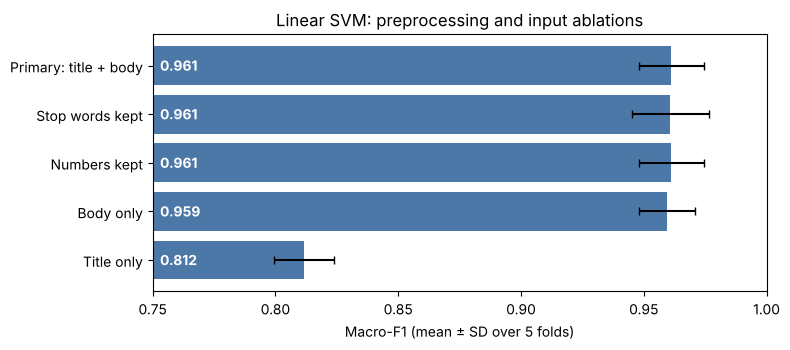

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ablations['configuration'][::-1], ablations['macro_f1'][::-1],
        xerr=ablations['macro_f1_sd'][::-1], color='#4C78A8', capsize=3)
ax.set_xlim(0.75, 1.0)
ax.set_xlabel('Macro-F1 (mean ± SD over 5 folds)')
ax.set_title('Linear SVM: preprocessing and input ablations')
for i, v in enumerate(ablations['macro_f1'][::-1]):
    ax.text(0.753, i, f'{v:.3f}', va='center', ha='left', color='white', fontweight='bold')
plt.tight_layout()
plt.savefig('../results/ablations.png', dpi=150)
plt.show()

pd.concat([baselines, ablations]).drop(columns='fold_vocab').round(4).to_csv(
    '../results/preliminary_results.csv', index=False)

**Reading the results.** The differences between preprocessing variants are smaller than the fold-to-fold standard deviation, so none of them is a meaningful change. The body carries almost all the signal; titles alone are much weaker, so the classifier is not relying on headline wording.

## 3 · Leakage check: most discriminative terms per class

Linear SVM fitted on all development articles (diagnostic only). If section markers or templates leaked into the text, they would appear here.

In [7]:
vec = tfidf()
X = vec.fit_transform(primary)
clf = LinearSVC(C=1.0, random_state=42).fit(X, y)
terms = np.array(vec.get_feature_names_out())
top = {c: terms[np.argsort(clf.coef_[list(clf.classes_).index(c)])[::-1][:15]] for c in CLASSES}
pd.DataFrame(top)

,sport,economy,health,arts,family
0,القدم,الشركات,الصحة,الفيلم,الاطفال
1,مباراة,مليار,الادوية,فيلم,النساء
2,لكرة,الاقتصاد,المرضي,مسلسل,الطفل
3,الدوري,النفط,الدم,الافلام,المراة
4,نادي,اسعار,الامراض,المسلسل,البشرة
5,كاس,الدولار,الاطباء,الفنان,الاسرة
6,النادي,شركة,تناول,الوثائقية,المدارس
7,كرة,المالية,العلاج,الممثل,طفلك
8,اللاعب,الاقتصادي,الاصابة,الوثائقي,الزواج
9,لاعب,الاقتصادية,الاشخاص,الفن,الامهات


In [8]:
# Direct search for possible section boilerplate in the raw development text
raw = (dev['title'] + ' ' + dev['content'])
for pattern in ['/sport/', '/ebusiness/', '/health/', '/arts/', '/family/', 'قسم الفن', 'صحة الجزيرة', 'الجزيرة نت']:
    hits = raw.str.contains(pattern, regex=False)
    print(f'{pattern:14} {hits.sum():4d} articles', dict(dev.loc[hits, 'section'].value_counts()))

/sport/           1 articles {'sport': np.int64(1)}
/ebusiness/       0 articles {}
/health/          0 articles {}
/arts/            0 articles {}
/family/          0 articles {}
قسم الفن          2 articles {'arts': np.int64(2)}
صحة الجزيرة       0 articles {}
الجزيرة نت       90 articles {'economy': np.int64(28), 'sport': np.int64(20), 'family': np.int64(19), 'health': np.int64(12), 'arts': np.int64(11)}
